In [1]:
import numpy as np, math, time, random, collections
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tictactoe import (empty_board, actions, result, terminal, utility, other,
                       show_board, random_player as ttt_random, play as ttt_play)

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
plt.rcParams['figure.dpi'] = 90
SEED = 2026
ALL_ROWS = []        # gom kết quả các ván đấu để lập bảng tổng hợp cuối báo cáo

In [2]:
def eval_fun(state, player='x'):
    """Heuristic cho trạng thái. Trả về (giá trị, terminal?)."""
    u = utility(state, player)
    if u is not None:                       # trạng thái kết thúc -> lợi ích thật
        return u, True
    score = 0
    board = np.array(state).reshape((3, 3))
    diagonals = np.array([[board[i][i] for i in range(3)], [board[i][2 - i] for i in range(3)]])
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row == ' '): score += .4
            if sum(row == other(player)) == 2 and any(row == ' '): score -= .4
    return score, False

# kiểm tra nhanh trên 4 bàn cờ mẫu của notebook gốc
b1 = empty_board()
b2 = empty_board(); b2[0] = b2[1] = b2[2] = 'x'
b3 = empty_board(); b3[0] = b3[1] = b3[3] = 'x'; b3[4] = b3[8] = 'o'
b4 = empty_board(); b4[0] = b4[3] = 'x'; b4[1] = b4[4] = 'o'
for name, b in [("rỗng", b1), ("x đã thắng", b2), ("x có 2 đường mở, o có 1", b3), ("x 2 quân dọc, o 2 quân dọc", b4)]:
    print(f"{name:32s} eval cho x = {eval_fun(b)}   eval cho o = {eval_fun(b, 'o')}")

rỗng                             eval cho x = (0, False)   eval cho o = (0, False)
x đã thắng                       eval cho x = (1, True)   eval cho o = (-1, True)
x có 2 đường mở, o có 1          eval cho x = (0.8, False)   eval cho o = (-0.8, False)
x 2 quân dọc, o 2 quân dọc       eval cho x = (0.0, False)   eval cho o = (0.0, False)


In [3]:
COUNT = 0   # số nút đã duyệt trong lần tìm kiếm hiện tại

def alpha_beta_search(board, cutoff=None, player='x'):
    """cutoff=None: Minimax + Alpha-Beta đầy đủ. Trả về dict(move, value, nodes, ms)."""
    global COUNT
    COUNT = 0
    t = time.perf_counter()
    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    return {"move": move, "value": value, "nodes": COUNT, "ms": 1000 * (time.perf_counter() - t)}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    global COUNT
    COUNT += 1
    v, is_terminal = eval_fun(state, player)
    if is_terminal or (cutoff is not None and depth >= cutoff):
        return v, None
    v, move = -math.inf, None
    for a in actions(state):
        v2, _ = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    global COUNT
    COUNT += 1
    v, is_terminal = eval_fun(state, player)
    if is_terminal or (cutoff is not None and depth >= cutoff):
        return v, None
    v, move = +math.inf, None
    for a in actions(state):
        v2, _ = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    return v, move

def move_values(board, player='x'):
    """Giá trị Minimax THẬT (tìm tới cuối ván) của từng nước đi hợp lệ, theo góc nhìn của `player`.
    Dùng làm 'đáp án chuẩn' để chấm chất lượng nước đi: nước đi tối ưu là nước có giá trị lớn nhất."""
    return {a: min_value_ab(result(board, player, a), player, -math.inf, math.inf, 1, None)[0] for a in actions(board)}

# Hai tác tử của đề + Alpha-Beta đầy đủ
def heuristic2_player(board, player='x'): return alpha_beta_search(board, cutoff=2, player=player)["move"]
def heuristic4_player(board, player='x'): return alpha_beta_search(board, cutoff=4, player=player)["move"]
def alpha_beta_player(board, player='x'): return alpha_beta_search(board, cutoff=None, player=player)["move"]

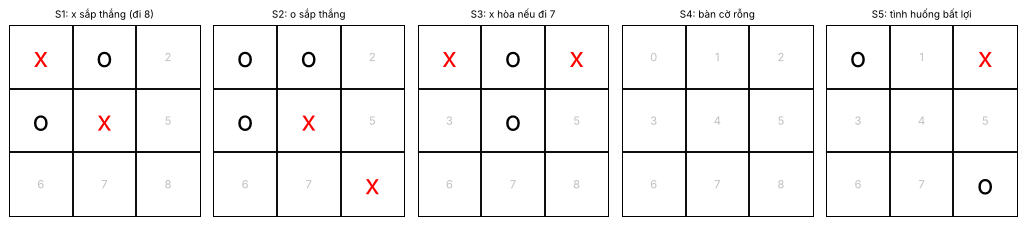

In [4]:
def board_from(x=(), o=()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

TEST = {
    "S1: x sắp thắng (đi 8)":   board_from(x=(0, 4), o=(1, 3)),
    "S2: o sắp thắng":          board_from(x=(4, 8), o=(0, 1, 3)),
    "S3: x hòa nếu đi 7":       board_from(x=(0, 2), o=(1, 4)),
    "S4: bàn cờ rỗng":          empty_board(),
    "S5: tình huống bất lợi":   board_from(x=(2,), o=(0, 8)),
}

def draw_boards(boards):
    fig, axes = plt.subplots(1, len(boards), figsize=(2.3 * len(boards), 2.7))
    for ax, (name, b) in zip(np.atleast_1d(axes), boards.items()):
        ax.set_xlim(-.5, 2.5); ax.set_ylim(2.5, -.5); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
        for k in (.5, 1.5): ax.axhline(k, color='k'); ax.axvline(k, color='k')
        for i in range(9):
            r, c = divmod(i, 3); s = b[i]
            ax.text(c, r, s if s != ' ' else str(i), ha='center', va='center',
                    fontsize=22 if s != ' ' else 9, color={'x': 'red', 'o': 'black', ' ': 'silver'}[s])
        ax.set_title(name, fontsize=8)
    plt.tight_layout(); plt.show()

draw_boards(TEST)

In [5]:
METHODS = [("Alpha-Beta đầy đủ", None), ("Heuristic AB, cutoff=2", 2), ("Heuristic AB, cutoff=4", 4)]
rows = []
for sname, b in TEST.items():
    mv = move_values(b); best = max(mv.values())
    for mname, cut in METHODS:
        runs = [alpha_beta_search(b, cut) for _ in range(5)]
        r = runs[0]; ms = min(x["ms"] for x in runs)
        rows.append({"Trạng thái": sname.split(':')[0], "Phương pháp": mname, "Nước đi": r["move"],
                     "Giá trị tìm kiếm": round(r["value"], 2), "Giá trị thật của nước đi": mv[r["move"]],
                     "Tối ưu?": "✔" if mv[r["move"]] == best else "✘", "Số nút": r["nodes"], "Thời gian (ms)": round(ms, 3)})
df_b4 = pd.DataFrame(rows)
display(df_b4)

summary = (df_b4.assign(opt=df_b4["Tối ưu?"].eq("✔"))
           .groupby("Phương pháp", sort=False)
           .agg(**{"Nước đi (S1..S5)": ("Nước đi", lambda s: ", ".join(map(str, s))),
                   "Tổng số nút": ("Số nút", "sum"), "Tổng thời gian (ms)": ("Thời gian (ms)", "sum"),
                   "Số trạng thái chọn nước tối ưu (/5)": ("opt", "sum")}))
summary["Tổng thời gian (ms)"] = summary["Tổng thời gian (ms)"].round(2)
display(summary)

,Trạng thái,Phương pháp,Nước đi,Giá trị tìm kiếm,Giá trị thật của nước đi,Tối ưu?,Số nút,Thời gian (ms)
0,S1,Alpha-Beta đầy đủ,2,1.0,1,✔,61,2.914
1,S1,"Heuristic AB, cutoff=2",8,1.0,1,✔,13,0.730
2,S1,"Heuristic AB, cutoff=4",2,1.0,1,✔,47,2.751
3,S2,Alpha-Beta đầy đủ,2,-1.0,-1,✔,15,0.589
4,S2,"Heuristic AB, cutoff=2",2,-1.0,-1,✔,11,0.470
5,S2,"Heuristic AB, cutoff=4",2,-1.0,-1,✔,15,0.589
6,S3,Alpha-Beta đầy đủ,7,0.0,0,✔,101,4.824
7,S3,"Heuristic AB, cutoff=2",7,-0.4,0,✔,21,1.150
8,S3,"Heuristic AB, cutoff=4",7,0.0,0,✔,81,4.386
9,S4,Alpha-Beta đầy đủ,0,0.0,0,✔,18297,861.958


,Nước đi (S1..S5),Tổng số nút,Tổng thời gian (ms),Số trạng thái chọn nước tối ưu (/5)
Phương pháp,,,,
Alpha-Beta đầy đủ,"2, 2, 7, 0, 1",18712,881.31,5
"Heuristic AB, cutoff=2","8, 2, 7, 0, 4",100,5.78,5
"Heuristic AB, cutoff=4","2, 2, 7, 4, 1",832,52.41,5


61 thế cờ kiểm thử


,cutoff,% nước đi tối ưu,Số nút TB,Thời gian TB (ms)
0,1,83.6,6.1,0.391
1,2,88.5,17.1,1.121
2,3,96.7,55.4,3.814
3,4,95.1,122.1,7.825
4,5,100.0,195.9,9.687
5,6,100.0,285.5,15.503
6,đầy đủ,100.0,562.8,29.833


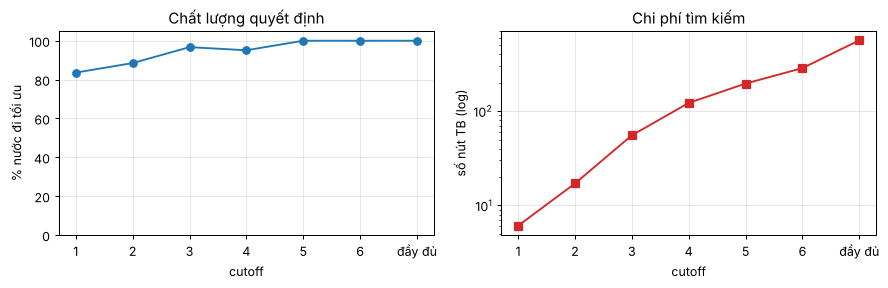

In [6]:
def random_positions(n_per_ply=20, plies=(2, 4, 6), seed=SEED):
    rng = np.random.RandomState(seed); out = [empty_board()]
    for p in plies:
        c = 0
        while c < n_per_ply:
            b = empty_board(); pl = 'x'; ok = True
            for _ in range(p):
                if terminal(b): ok = False; break
                b = result(b, pl, rng.choice(actions(b))); pl = other(pl)
            if ok and not terminal(b): out.append(b); c += 1
    return out

POS = random_positions()
TRUE = [move_values(b) for b in POS]
is_opt = lambda i, a: TRUE[i][a] == max(TRUE[i].values())
print(len(POS), "thế cờ kiểm thử")

rows = []
for cut in [1, 2, 3, 4, 5, 6, None]:
    res = [alpha_beta_search(b, cut) for b in POS]
    rows.append({"cutoff": "đầy đủ" if cut is None else cut,
                 "% nước đi tối ưu": round(100 * np.mean([is_opt(i, r["move"]) for i, r in enumerate(res)]), 1),
                 "Số nút TB": round(np.mean([r["nodes"] for r in res]), 1),
                 "Thời gian TB (ms)": round(np.mean([r["ms"] for r in res]), 3)})
df_cut = pd.DataFrame(rows); display(df_cut)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(df_cut["cutoff"].astype(str), df_cut["% nước đi tối ưu"], 'o-'); ax[0].set_ylim(0, 105)
ax[0].set_xlabel("cutoff"); ax[0].set_ylabel("% nước đi tối ưu"); ax[0].set_title("Chất lượng quyết định"); ax[0].grid(alpha=.3)
ax[1].semilogy(df_cut["cutoff"].astype(str), df_cut["Số nút TB"], 's-', color='tab:red'); ax[1].set_xlabel("cutoff")
ax[1].set_ylabel("số nút TB (log)"); ax[1].set_title("Chi phí tìm kiếm"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Nhận xét (61 thế cờ ngẫu nhiên).**

| cutoff | 1 | 2 | 3 | 4 | 5 | 6 | đầy đủ |
|---|---|---|---|---|---|---|---|
| % nước tối ưu | 83,6 | 88,5 | 96,7 | 95,1 | 100 | 100 | 100 |
| số nút TB | 6,1 | 17,1 | 55,4 | 122,1 | 195,9 | 285,5 | 562,8 |
| thời gian TB (ms) | 0,39 | 1,12 | 3,81 | 7,83 | 9,69 | 15,5 | 29,8 |

* **Đánh đổi độ sâu – chất lượng:** tăng cutoff làm số nút và thời gian tăng gần như đều, còn chất lượng tăng nhanh ở các độ sâu đầu (83,6 % → 96,7 % từ cutoff 1 → 3) rồi bão hòa. Từ cutoff = 5 đã đạt 100 % trên tập này với ~35 % số nút của tìm kiếm đầy đủ (195,9 so với 562,8).
* Chất lượng **không hoàn toàn đơn điệu**: cutoff 4 (95,1 %) thấp hơn cutoff 3 (96,7 %). Chênh lệch chỉ là 1 thế cờ trên 61 nên không đủ để kết luận; có thể do hiệu ứng độ sâu chẵn/lẻ của heuristic (đánh giá sau lượt đối thủ hay sau lượt mình).
* Số nút trung bình của tìm kiếm đầy đủ (562,8) bị kéo thấp vì tập có nhiều thế cờ đã gần kết thúc; với bàn rỗng riêng nó là 18 297.

In [7]:
class Timed:
    """Bọc một tác tử để đo thời gian trung bình mỗi nước đi (ms)."""
    def __init__(self, f): self.f, self.t = f, []
    def __call__(self, board, player='x'):
        t = time.perf_counter(); a = self.f(board, player); self.t.append(time.perf_counter() - t); return a
    @property
    def ms(self): return 1000 * float(np.mean(self.t))

def versus(agent, name, opponent=ttt_random, opp_name="Random", n=100, seed=SEED, group="TTT"):
    """Tác tử đấu n ván khi đi trước và n ván khi đi sau. Trả về DataFrame 2 dòng."""
    out = []
    np.random.seed(seed); random.seed(seed)
    t = Timed(agent); r = ttt_play(t, opponent, N=n)
    out.append({"Tác tử": name, "Đối thủ": opp_name, "Vai": "X (đi trước)", "Số ván": n,
                "Thắng": r['x'], "Hòa": r['d'], "Thua": r['o'], "Thời gian TB/nước (ms)": round(t.ms, 3)})
    np.random.seed(seed + 1); random.seed(seed + 1)
    t = Timed(agent); r = ttt_play(opponent, t, N=n)
    out.append({"Tác tử": name, "Đối thủ": opp_name, "Vai": "O (đi sau)", "Số ván": n,
                "Thắng": r['o'], "Hòa": r['d'], "Thua": r['x'], "Thời gian TB/nước (ms)": round(t.ms, 3)})
    for o in out: ALL_ROWS.append(dict(o, group=group))
    return pd.DataFrame(out)

# baseline Random vs Random để thấy lợi thế đi trước (1000 ván, dùng làm mốc so sánh)
np.random.seed(SEED); rr = ttt_play(ttt_random, ttt_random, N=1000)
print("Random vs Random (1000 ván): X thắng", rr['x'], "| O thắng", rr['o'], "| hòa", rr['d'])

df_h = pd.concat([versus(heuristic2_player, "Heuristic AB (cutoff=2)"),
                  versus(heuristic4_player, "Heuristic AB (cutoff=4)")], ignore_index=True)
display(df_h)

Random vs Random (1000 ván): X thắng 596 | O thắng 282 | hòa 122


,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước (ms)
0,Heuristic AB (cutoff=2),Random,X (đi trước),100,97,3,0,1.334
1,Heuristic AB (cutoff=2),Random,O (đi sau),100,86,11,3,1.353
2,Heuristic AB (cutoff=4),Random,X (đi trước),100,99,1,0,14.698
3,Heuristic AB (cutoff=4),Random,O (đi sau),100,80,20,0,10.350


**Nhận xét.**
* **Lợi thế đi trước** rất rõ ngay cả khi cả hai đánh ngẫu nhiên: Random vs Random (1000 ván) X thắng 59,6 %, O thắng 28,2 %, hòa 12,2 %.
* Heuristic cutoff=2 đạt 97 thắng / 3 hòa / 0 thua khi đi trước và 86 / 11 / 3 khi đi sau; cutoff=4 đạt 99 / 1 / 0 và 80 / 20 / 0. Cả hai gần như không thua trước Random.
* Cutoff = 4 **không thắng nhiều hơn** cutoff = 2 nhưng chơi chắc hơn (0 ván thua khi đi sau, thay vì 3) đổi lại nhiều hòa hơn; thời gian mỗi nước tăng từ ~1,3 ms lên ~14,7 ms (≈ 11 lần). Với đối thủ Random, độ sâu 2 đã đủ để thắng đa số ván; chênh lệch chất lượng chỉ lộ ra khi đối thủ mạnh (xem 4.7).

In [8]:
def one_game(x, o):
    r = ttt_play(x, o, N=1)
    return "X thắng" if r['x'] else ("O thắng" if r['o'] else "Hòa")

pairs = [("heuristic2", heuristic2_player, "Alpha-Beta đầy đủ", alpha_beta_player),
         ("heuristic4", heuristic4_player, "Alpha-Beta đầy đủ", alpha_beta_player),
         ("heuristic2", heuristic2_player, "heuristic4", heuristic4_player)]
rows = []
for n1, f1, n2, f2 in pairs:
    t1, t2 = Timed(f1), Timed(f2); res1 = one_game(t1, t2)
    t3, t4 = Timed(f2), Timed(f1); res2 = one_game(t3, t4)
    rows.append({"Cặp đấu": f"{n1} vs {n2}", f"{n1} đi trước": res1, f"{n1} đi sau": res2,
                 f"ms/nước {n1}": round((t1.ms + t4.ms) / 2, 3), f"ms/nước {n2}": round((t2.ms + t3.ms) / 2, 3)})
df_hh = pd.DataFrame(rows); display(df_hh.T)

,0,1,2
Cặp đấu,heuristic2 vs Alpha-Beta đầy đủ,heuristic4 vs Alpha-Beta đầy đủ,heuristic2 vs heuristic4
heuristic2 đi trước,Hòa,NaN,Hòa
heuristic2 đi sau,X thắng,NaN,Hòa
ms/nước heuristic2,1.36,NaN,1.628
ms/nước Alpha-Beta đầy đủ,138.576,106.145,NaN
heuristic4 đi trước,NaN,Hòa,NaN
heuristic4 đi sau,NaN,Hòa,NaN
ms/nước heuristic4,NaN,8.64,13.878


**Nhận xét.** Mỗi ô là kết quả một ván (tác tử xác định, không ngẫu nhiên). Khi đối đầu với Alpha-Beta đầy đủ (chơi tối ưu), heuristic cutoff=4 hòa cả hai vai, còn heuristic cutoff=2 hòa khi đi trước nhưng **thua** khi đi sau (ô "X thắng" ở cột đi sau là Alpha-Beta đầy đủ đi trước thắng). Heuristic2 vs heuristic4 hòa cả hai vai. Vậy cutoff = 4 đủ để không thua trước người chơi tối ưu trên Tic-Tac-Toe, còn cutoff = 2 thì chưa.
(Các ô NaN chỉ là cột không áp dụng cho cặp đấu đó.)